<a href="https://colab.research.google.com/github/andreaprifti19/SINDy-Teaching-Usecases/blob/main/notebooks/02_lorenz_system.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Use Case 2: Discovering the Equations of the Lorenz System with SINDy

In Use Case 1 we let SINDy find the equations of a damped oscillator. That system was simple: two variables, only linear terms, and a smooth spiral towards rest.

Now we take the next step. The **Lorenz system** has three variables, **nonlinear** terms, and it is **chaotic**: its motion never repeats and never settles down. It is the classic test system of the original SINDy paper (Brunton et al., 2016), and it shows clearly where equation discovery becomes hard.

We use exactly the same workflow as in Use Case 1, so you can compare the two notebooks step by step.

**What is new compared to Use Case 1**

- Three variables and nonlinear terms ($xz$, $xy$), so the candidate library must contain products of variables.
- Chaos: a correct model still drifts away from the data after some time. We need new ways to check if a model is correct.
- A new tool, **Ensemble-SINDy**, which tells us how much we can trust each discovered term.

**What you will learn**

1. Why the Lorenz system is a harder test for SINDy than the oscillator.
2. How to run SINDy on a nonlinear system with three variables.
3. How to validate a model of a chaotic system, when comparing curves point by point no longer works.
4. When SINDy fails: noise, too much smoothing, too little data, or an unsuitable library.

**How to use this notebook**

- Run the cells **from top to bottom**, in order. Later cells use variables from earlier cells.
- If you change something, use *Runtime → Restart and run all* so that every result comes from the same run.
- All randomness uses a fixed seed, so you should see exactly the same numbers as written in the text.

**Contents**

1. Setup
2. The physical system
3. Generating the data
4. Discovering the equations with SINDy
5. Validation: is the discovered model correct?
6. Robustness experiments: noise, smoothing, Ensemble-SINDy, data quantity, candidate library
7. Summary
8. Exercises

## 1. Setup

We install the same PySINDy version as in Use Case 1 (`2.1.0`), so both notebooks behave the same.

In [18]:
!pip install pysindy==2.1.0

The imports and the reproducibility settings are the same as in Use Case 1, with one addition:

- **Warnings.** We hide the same two numerical warnings as before. In addition, with very noisy data STLSQ sometimes removes *every* term and then prints a warning. In our tables such a fit simply counts as a failure, so we hide this one message too. All other warnings are still shown.
- **Random seed.** `SEED = 0` makes the random noise identical on every run and every computer. (Section 6 explains how every noisy dataset is built from this seed.)

In [19]:
import warnings

import numpy as np
import scipy
import sklearn
import matplotlib
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.linalg import LinAlgWarning
from sklearn.metrics import mean_absolute_error
from sklearn.exceptions import ConvergenceWarning
import pysindy as ps

# Same two warnings as in Use Case 1 (they appear often in the robustness sweeps).
warnings.filterwarnings("ignore", category=LinAlgWarning)
warnings.filterwarnings("ignore", category=ConvergenceWarning)
# Very noisy fits sometimes lose every term. We count those as failures,
# so the warning itself is not needed.
warnings.filterwarnings("ignore", message="Sparsity parameter is too big")

# Fixed seed -> identical noise, identical numbers, on every run and every machine.
SEED = 0

print("pysindy      ", ps.__version__)
print("numpy        ", np.__version__)
print("scipy        ", scipy.__version__)
print("scikit-learn ", sklearn.__version__)
print("matplotlib   ", matplotlib.__version__)

pysindy       2.1.0
numpy         2.1.3
scipy         1.16.3
scikit-learn  1.6.1
matplotlib    3.10.0


All figures are saved into the same `figures/` folder as in Use Case 1. The file names start with `lorenz_`, so they do not overwrite the figures of the first notebook.

In [20]:
import os
# In Colab: saves to "figures/". Run locally from the repo's notebooks/ folder: saves to the repo's figures/.
FIG_DIR = "../figures" if os.path.isdir("../figures") else "figures"
os.makedirs(FIG_DIR, exist_ok=True)

## 2. The physical system

In 1963, the meteorologist Edward Lorenz built a strongly simplified model of **convection**: a layer of fluid that is heated from below and cooled from above. Warm fluid rises, cool fluid sinks, and rolls of circulating fluid form. Lorenz reduced this to three variables:

- $x$: how fast the convection rolls turn (the sign gives the direction),
- $y$: the temperature difference between the rising and the sinking fluid,
- $z$: how much the vertical temperature profile differs from a straight line.

The equations are

$$\dot{x} = \sigma\,(y - x)$$
$$\dot{y} = x\,(\rho - z) - y$$
$$\dot{z} = x\,y - \beta\,z$$

**No rewriting needed.** In Use Case 1 we first had to turn a second-order equation into two first-order equations. The Lorenz system is already first-order: each variable has exactly one time derivative on the left side. So it is directly in the form that SINDy needs.

**Nonlinear terms.** The products $x\,z$ (inside $x(\rho - z)$) and $x\,y$ make the system nonlinear. They are the reason why Lorenz is chaotic, and they are the reason why our library needs terms of degree 2. For the oscillator, degree 1 would have been enough.

**Parameters.** We use the classic values from Lorenz (1963), which are also used in the SINDy paper:

- $\sigma = 10$ (Prandtl number: how fast heat spreads compared to motion),
- $\rho = 28$ (Rayleigh number, scaled: how strongly the layer is heated),
- $\beta = 8/3$ (a geometry factor of the convection rolls).

For these values the system is **chaotic**. It is completely deterministic (no randomness at all), but two starting points that are extremely close drift apart exponentially fast. This is the famous *butterfly effect*. We will see it directly in Section 5.

**The ground truth.** As in Use Case 1, `TRUE_COEF` writes the correct answer as a table. With a degree-2 library and three variables there are 10 candidate terms per equation:

| | $1$ | $x$ | $y$ | $z$ | $x^2$ | $xy$ | $xz$ | $y^2$ | $yz$ | $z^2$ |
|---|---|---|---|---|---|---|---|---|---|---|
| $\dot{x}$ | 0 | −10 | 10 | 0 | 0 | 0 | 0 | 0 | 0 | 0 |
| $\dot{y}$ | 0 | 28 | −1 | 0 | 0 | 0 | −1 | 0 | 0 | 0 |
| $\dot{z}$ | 0 | 0 | 0 | −8/3 | 0 | 1 | 0 | 0 | 0 | 0 |

Only 7 of the 30 entries are non-zero, so the system is again **sparse**. Note two things for later:

- The coefficients have very different sizes: from 1 up to 28.
- The **smallest** true coefficient is 1 (the $-y$ term and the $-xz$ term in $\dot{y}$, and the $xy$ term in $\dot{z}$). This matters when we choose the threshold.

In [21]:
sigma = 10.0       # Prandtl number
rho   = 28.0       # (scaled) Rayleigh number
beta  = 8.0 / 3.0  # geometry factor

def lorenz(t, state):
    x, y, z = state
    return [sigma * (y - x),
            x * (rho - z) - y,
            x * y - beta * z]

# The answer we want SINDy to recover, written as a coefficient matrix.
# Rows = equations (x', y', z'); columns = library terms
#             1      x      y      z    x^2   x*y   x*z   y^2   y*z   z^2
TRUE_COEF = np.array([
    [0.0, -sigma, sigma,   0.0,  0.0,  0.0,  0.0,  0.0,  0.0,  0.0],   # x' = sigma (y - x)
    [0.0,    rho,  -1.0,   0.0,  0.0,  0.0, -1.0,  0.0,  0.0,  0.0],   # y' = rho x - y - x z
    [0.0,    0.0,   0.0, -beta,  0.0,  1.0,  0.0,  0.0,  0.0,  0.0],   # z' = x y - beta z
])

## 3. Generating the data

We again create the measurements by simulation. The settings are the same as in the Lorenz example of the PySINDy documentation, so you can compare with it:

- `dt = 0.002`: one measurement every 0.002 time units. This is 5 times finer than in Use Case 1, because the Lorenz system changes much faster.
- `t`: 10 time units, that is 5000 time points.
- `x0 = [-8, 8, 27]`: the starting point.
- `solve_ivp` with strict tolerances (`rtol`, `atol`) as in Use Case 1, so that the numerical error of the simulation is negligible.

The Lorenz equations have no physical unit of time, so we simply speak of *time units*.

Because we will simulate the Lorenz system several times (also from other starting points), we put the solver call into a small function `simulate_lorenz`. As before, `.T` gives the data matrix the shape PySINDy expects: one **row per time point**, one **column per variable**.

In [22]:
dt = 0.002                       # sampling interval
t = np.arange(0, 10, dt)         # 10 time units, 5000 samples
x0 = [-8.0, 8.0, 27.0]           # starting point

def simulate_lorenz(x0, t):
    '''Simulate the true Lorenz system; returns an array of shape (len(t), 3).'''
    sol = solve_ivp(lorenz, (t[0], t[-1]), x0, t_eval=t, rtol=1e-10, atol=1e-12)
    return sol.y.T

X = simulate_lorenz(x0, t)       # column 0 = x, column 1 = y, column 2 = z
print("Data matrix shape:", X.shape)

Data matrix shape: (5000, 3)


As always, we look at the data before running any algorithm.

- **Left, time series:** $x$, $y$ and $z$ over time. The motion is irregular. $x$ and $y$ oscillate around a positive value for a while, then suddenly jump to negative values, and back again, without any regular pattern.
- **Right, phase portrait in 3D:** the same data without time. The trajectory traces the famous **butterfly-shaped Lorenz attractor**. It has two "wings". On each wing the trajectory spirals outwards, until it jumps to the other wing.

Compare this with Use Case 1: there the phase portrait was a single spiral into one point. Here the trajectory never comes to rest and never repeats itself.

Each jump from one wing to the other is a sign change of $x$. We count these **wing switches**, because they will be useful in the data-quantity experiment (Section 6.4).

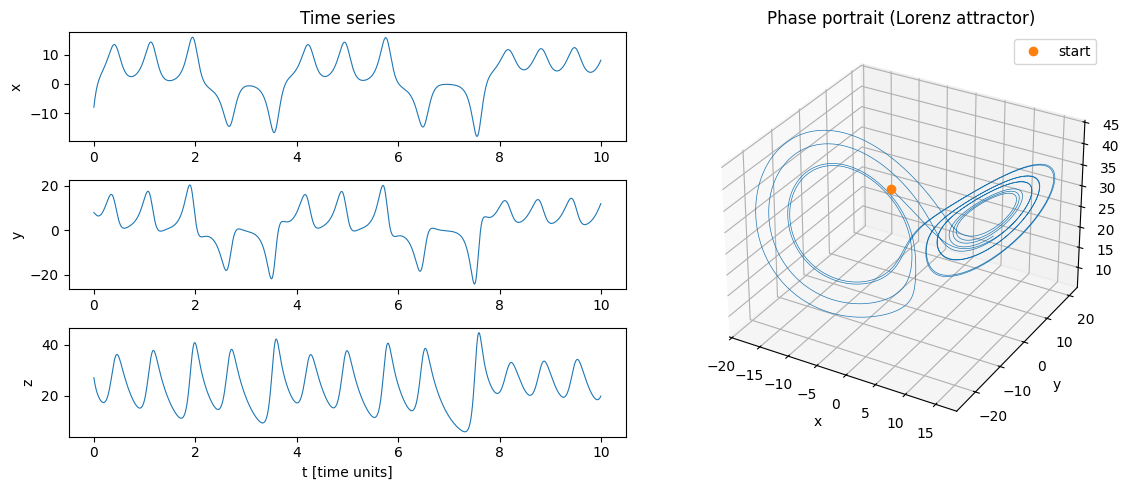

Wing switches at t = [0.08 2.2  3.78 6.01 7.75]


In [23]:
fig = plt.figure(figsize=(12, 5))
for i, name in enumerate(["x", "y", "z"]):
    ax = fig.add_subplot(3, 2, 2 * i + 1)
    ax.plot(t, X[:, i], lw=0.8)
    ax.set_ylabel(name)
fig.axes[0].set_title("Time series")
ax.set_xlabel("t [time units]")

ax3d = fig.add_subplot(1, 2, 2, projection="3d")
ax3d.plot(X[:, 0], X[:, 1], X[:, 2], lw=0.5)
ax3d.plot(*X[0], "o", label="start")
ax3d.set_xlabel("x"); ax3d.set_ylabel("y"); ax3d.set_zlabel("z")
ax3d.set_title("Phase portrait (Lorenz attractor)"); ax3d.legend()
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/lorenz_data_overview.png", dpi=200, bbox_inches="tight")
plt.show()

# A wing switch is a sign change of x.
switch_times = t[1:][np.diff(np.sign(X[:, 0])) != 0]
print("Wing switches at t =", np.round(switch_times, 2))

In [24]:
model = ps.SINDy(
    differentiation_method=ps.FiniteDifference(order=2),
    feature_library=ps.PolynomialLibrary(degree=2),
    optimizer=ps.STLSQ(threshold=0.5),
)
model.fit(X, t=dt, feature_names=["x", "y", "z"])

print("Candidate library:", model.get_feature_names())
print("\nDiscovered equations:")
model.print()

Candidate library: ['1', 'x', 'y', 'z', 'x^2', 'x y', 'x z', 'y^2', 'y z', 'z^2']

Discovered equations:
(x)' = -9.999 x +  9.999 y
(y)' =  27.992 x + -0.999 y + -1.000 x z
(z)' = -2.666 z +  1.000 x y


In [25]:
def check_recovery(model, true_coef):
    '''Return (correct sparsity pattern?, max abs coefficient error).'''
    found = model.optimizer.coef_
    same_structure = np.array_equal(true_coef != 0, found != 0)
    return same_structure, np.abs(found - true_coef).max()

ok, max_err = check_recovery(model, TRUE_COEF)
print(f"Correct sparsity pattern : {ok}")
print(f"Max coefficient error    : {max_err:.2e}")
print(f"Mean abs coefficient err : {mean_absolute_error(TRUE_COEF, model.optimizer.coef_):.2e}")
print(f"R^2 on derivatives       : {model.score(X, t=dt):.6f}")

Correct sparsity pattern : True
Max coefficient error    : 7.77e-03
Mean abs coefficient err : 3.82e-04
R^2 on derivatives       : 1.000000


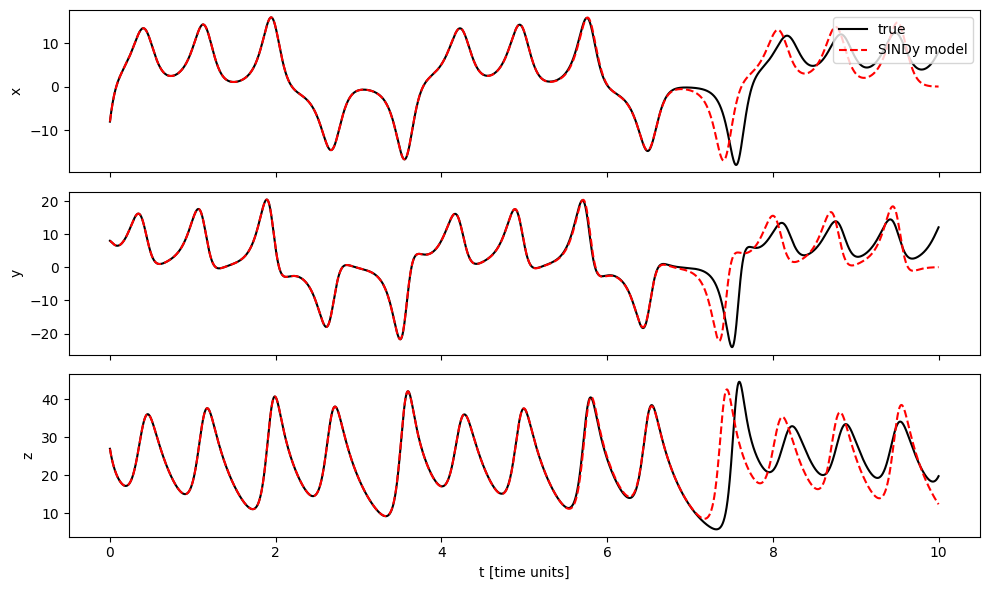

In [26]:
# Forward simulation from the same starting point, using only the discovered equations
X_sim = model.simulate(x0, t)

fig, ax = plt.subplots(3, 1, figsize=(10, 6), sharex=True)
for i, name in enumerate(["x", "y", "z"]):
    ax[i].plot(t, X[:, i], "k", label="true")
    ax[i].plot(t, X_sim[:, i], "r--", label="SINDy model")
    ax[i].set_ylabel(name)
ax[0].legend(loc="upper right"); ax[2].set_xlabel("t [time units]")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/lorenz_forward_simulation_clean.png", dpi=200, bbox_inches="tight")
plt.show()

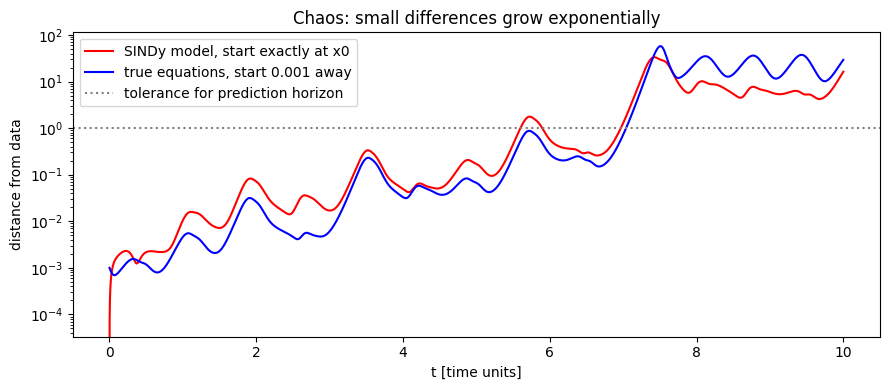

Prediction horizon, SINDy model                   : 5.60
Prediction horizon, true equations started 0.001 off: 7.04


In [27]:
def prediction_horizon(X_pred, X_true, tol=1.0):
    '''First time at which the prediction is more than `tol` away from the truth.'''
    err = np.linalg.norm(X_pred - X_true[:len(X_pred)], axis=1)
    above = np.nonzero(err > tol)[0]
    return t[above[0]] if above.size else t[len(err) - 1]

# The TRUE equations, started 0.001 away from x0
X_shift = simulate_lorenz([x0[0] + 0.001, x0[1], x0[2]], t)

fig, ax = plt.subplots(figsize=(9, 4))
ax.semilogy(t, np.linalg.norm(X_sim - X, axis=1), "r", label="SINDy model, start exactly at x0")
ax.semilogy(t, np.linalg.norm(X_shift - X, axis=1), "b", label="true equations, start 0.001 away")
ax.axhline(1.0, color="gray", ls=":", label="tolerance for prediction horizon")
ax.set_xlabel("t [time units]"); ax.set_ylabel("distance from data")
ax.set_title("Chaos: small differences grow exponentially"); ax.legend()
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/lorenz_butterfly_effect.png", dpi=200, bbox_inches="tight")
plt.show()

print(f"Prediction horizon, SINDy model                   : {prediction_horizon(X_sim, X):.2f}")
print(f"Prediction horizon, true equations started 0.001 off: {prediction_horizon(X_shift, X):.2f}")

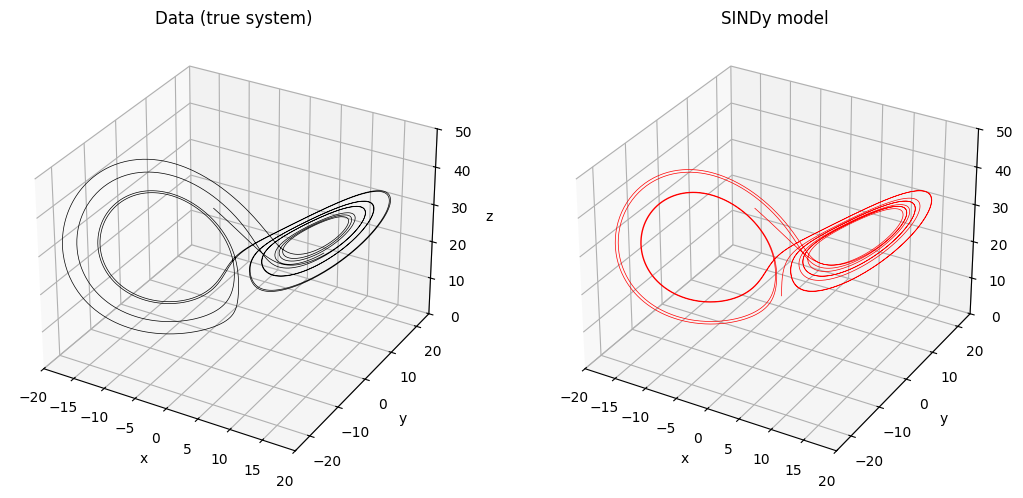

              x       y       z
mean data : [ 2.65  2.81 23.46]
mean model: [ 2.47  2.55 23.44]
std  data : [7.4  8.53 8.56]
std  model: [7.43 8.61 8.56]


In [28]:
fig = plt.figure(figsize=(11, 5))
for k, (data, title) in enumerate([(X, "Data (true system)"), (X_sim, "SINDy model")]):
    ax = fig.add_subplot(1, 2, k + 1, projection="3d")
    ax.plot(data[:, 0], data[:, 1], data[:, 2], lw=0.5, color="k" if k == 0 else "r")
    ax.set_xlim(-20, 20); ax.set_ylim(-25, 25); ax.set_zlim(0, 50)   # same axes for both
    ax.set_xlabel("x"); ax.set_ylabel("y"); ax.set_zlabel("z"); ax.set_title(title)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/lorenz_attractor_comparison.png", dpi=200, bbox_inches="tight")
plt.show()

print("              x       y       z")
print("mean data :", np.round(X.mean(axis=0), 2))
print("mean model:", np.round(X_sim.mean(axis=0), 2))
print("std  data :", np.round(X.std(axis=0), 2))
print("std  model:", np.round(X_sim.std(axis=0), 2))

In [29]:
N_TRIALS = 10   # independent noise draws per setting -> success rate instead of one lucky/unlucky run

def fit_sindy(X_data, diff_method=None, library=None, threshold=0.5, ensemble=False):
    '''Fit SINDy with the notebook's default settings unless overridden.
    ensemble=True wraps STLSQ into Ensemble-SINDy (Section 6.3).'''
    optimizer = ps.STLSQ(threshold=threshold)
    if ensemble:
        optimizer = ps.EnsembleOptimizer(optimizer, bagging=True, n_models=50)
        np.random.seed(SEED)   # the ensemble draws its random samples with NumPy's global generator
    mdl = ps.SINDy(
        differentiation_method=diff_method or ps.FiniteDifference(order=2),
        feature_library=library or ps.PolynomialLibrary(degree=2),
        optimizer=optimizer,
    )
    mdl.fit(X_data, t=dt, feature_names=["x", "y", "z"])
    return mdl

def noisy_copy(noise, trial):
    '''Copy of X with Gaussian noise (noise = fraction of each variable's std).
    The same (noise, trial) pair always gives exactly the same noise draw.'''
    rng = np.random.default_rng([SEED, trial, round(noise * 1000)])
    return X + rng.normal(0, noise * X.std(axis=0), X.shape)

def run_trials(noise, n_samples=len(t), n_trials=N_TRIALS, **fit_kwargs):
    '''Fit SINDy on n_trials noisy copies of the first n_samples data points.
    Returns (success rate, median max-coefficient error).'''
    oks, errs = [], []
    for trial in range(n_trials):
        X_noisy = noisy_copy(noise, trial)
        ok, err = check_recovery(fit_sindy(X_noisy[:n_samples], **fit_kwargs), TRUE_COEF)
        oks.append(ok); errs.append(err)
    return np.mean(oks), np.median(errs)

In [30]:
noise_levels = [0.0, 0.01, 0.02, 0.05, 0.10, 0.20]
smoothed = ps.SmoothedFiniteDifference(smoother_kws={"window_length": 51, "polyorder": 3})

results = []
for nl in noise_levels:
    sr_fd,  e_fd  = run_trials(nl)
    sr_sfd, e_sfd = run_trials(nl, diff_method=smoothed)
    results.append((nl, sr_fd, e_fd, sr_sfd, e_sfd))

print(f"{'noise':>6} | {'FiniteDifference':>24} | {'SmoothedFiniteDiff':>24}")
print(f"{'':>6} | {'success rate':>13} {'median err':>10} | {'success rate':>13} {'median err':>10}")
for nl, sr_fd, e_fd, sr_sfd, e_sfd in results:
    print(f"{nl*100:5.0f}% | {sr_fd*100:12.0f}% {e_fd:10.3f} | {sr_sfd*100:12.0f}% {e_sfd:10.3f}")

 noise |         FiniteDifference |       SmoothedFiniteDiff
       |  success rate median err |  success rate median err
    0% |          100%      0.008 |          100%      0.038
    1% |          100%      0.052 |          100%      0.038
    2% |          100%      0.225 |          100%      0.064
    5% |           40%      1.858 |          100%      0.144
   10% |            0%      3.775 |           70%      0.334
   20% |            0%      9.061 |           10%      2.277


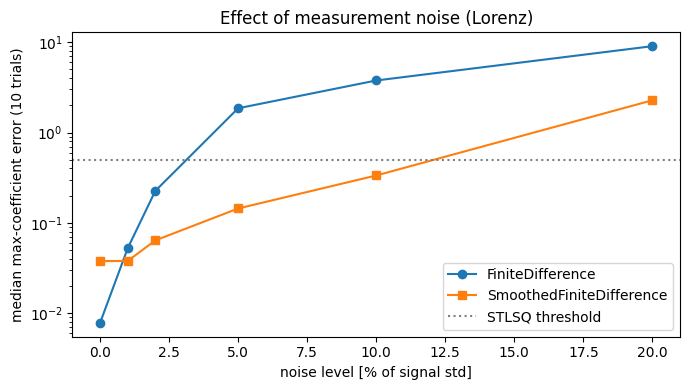

In [31]:
fig, ax = plt.subplots(figsize=(7, 4))
nl = [r[0] * 100 for r in results]
ax.plot(nl, [r[2] for r in results], "o-", label="FiniteDifference")
ax.plot(nl, [r[4] for r in results], "s-", label="SmoothedFiniteDifference")
ax.axhline(0.5, color="gray", ls=":", label="STLSQ threshold")
ax.set_xlabel("noise level [% of signal std]"); ax.set_ylabel(f"median max-coefficient error ({N_TRIALS} trials)")
ax.set_yscale("log"); ax.legend(); ax.set_title("Effect of measurement noise (Lorenz)")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/lorenz_noise_sweep.png", dpi=200, bbox_inches="tight")
plt.show()

In [32]:
X_noisy = noisy_copy(0.10, trial=0)         # the first of the ten 10%-noise datasets
model_fd  = fit_sindy(X_noisy)
model_sfd = fit_sindy(X_noisy, diff_method=smoothed)
print("--- 10% noise, FiniteDifference ---")
model_fd.print()
print("\n--- 10% noise, SmoothedFiniteDifference ---")
model_sfd.print()

--- 10% noise, FiniteDifference ---
(x)' = -5.180 1 +  2.399 y
(y)' = -0.605 1 +  29.273 x + -1.604 y + -1.018 x z
(z)' = -1.418 1 + -2.565 z +  0.974 x y

--- 10% noise, SmoothedFiniteDifference ---
(x)' = -9.977 x +  10.001 y
(y)' =  27.888 x + -0.941 y + -0.998 x z
(z)' = -2.655 z +  0.993 x y


         FiniteDifference: prediction horizon = 0.01 time units
 SmoothedFiniteDifference: prediction horizon = 1.65 time units


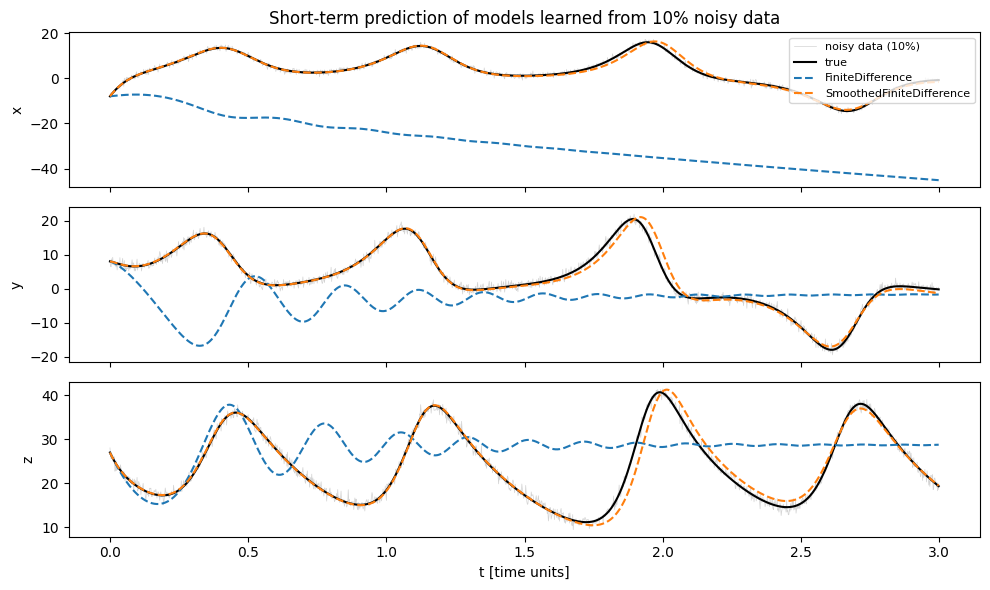

In [33]:
t_short = t[:1500]                      # first 3 time units
models = {"FiniteDifference": model_fd, "SmoothedFiniteDifference": model_sfd}

fig, ax = plt.subplots(3, 1, figsize=(10, 6), sharex=True)
for i, name in enumerate(["x", "y", "z"]):
    ax[i].plot(t_short, X_noisy[:1500, i], color="lightgray", lw=0.5, label="noisy data (10%)")
    ax[i].plot(t_short, X[:1500, i], "k", label="true")
    ax[i].set_ylabel(name)
for label, mdl in models.items():
    X_pred = mdl.simulate(x0, t_short)
    for i in range(3):
        ax[i].plot(t_short[:len(X_pred)], X_pred[:, i], "--", label=label)
    print(f"{label:>25}: prediction horizon = {prediction_horizon(X_pred, X):.2f} time units")
ax[0].legend(loc="upper right", fontsize=8); ax[2].set_xlabel("t [time units]")
ax[0].set_title("Short-term prediction of models learned from 10% noisy data")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/lorenz_simulation_10pct_noise.png", dpi=200, bbox_inches="tight")
plt.show()

In [34]:
print(f"{'window':>7} {'width':>7} | {'clean data':>16} | {'5% noise':>24} | {'10% noise':>24}")
print(f"{'':>7} {'':>7} | {'correct?':>8} {'max err':>7} | {'success rate':>13} {'median err':>10} | {'success rate':>13} {'median err':>10}")
for w in [21, 51, 101]:
    smoother = ps.SmoothedFiniteDifference(smoother_kws={"window_length": w, "polyorder": 3})
    ok_clean, err_clean = run_trials(0.0, n_trials=1, diff_method=smoother)
    sr5,  e5  = run_trials(0.05, diff_method=smoother)
    sr10, e10 = run_trials(0.10, diff_method=smoother)
    print(f"{w:7d} {w*dt:7.2f} | {str(bool(ok_clean)):>8} {err_clean:7.3f} | "
          f"{sr5*100:12.0f}% {e5:10.3f} | {sr10*100:12.0f}% {e10:10.3f}")

print("\n--- clean data, window_length = 101 ---")
wide = ps.SmoothedFiniteDifference(smoother_kws={"window_length": 101, "polyorder": 3})
fit_sindy(X, diff_method=wide).print()

 window   width |       clean data |                 5% noise |                10% noise
                | correct? max err |  success rate median err |  success rate median err
     21    0.04 |     True   0.008 |           80%      0.183 |           60%      0.555
     51    0.10 |     True   0.038 |          100%      0.144 |           70%      0.334
    101    0.20 |    False   0.524 |           20%      0.732 |           30%      0.818

--- clean data, window_length = 101 ---
(x)' = -9.991 x +  9.993 y
(y)' =  27.518 x + -0.915 y + -0.988 x z
(z)' = -0.524 1 + -2.626 z +  0.996 x y


In [35]:
sr_single,   e_single   = run_trials(0.10, diff_method=smoothed)
sr_ensemble, e_ensemble = run_trials(0.10, diff_method=smoothed, ensemble=True)
print("10% noise, smoothed derivatives")
print(f"  single SINDy fit : success rate {sr_single*100:3.0f}%, median max error {e_single:.3f}")
print(f"  Ensemble-SINDy   : success rate {sr_ensemble*100:3.0f}%, median max error {e_ensemble:.3f}")

10% noise, smoothed derivatives
  single SINDy fit : success rate  70%, median max error 0.334
  Ensemble-SINDy   : success rate  80%, median max error 0.300


Ensemble model (median coefficients):
(x)' = -9.971 x +  9.991 y
(y)' =  27.895 x + -0.934 y + -0.998 x z
(z)' = -2.650 z +  0.993 x y


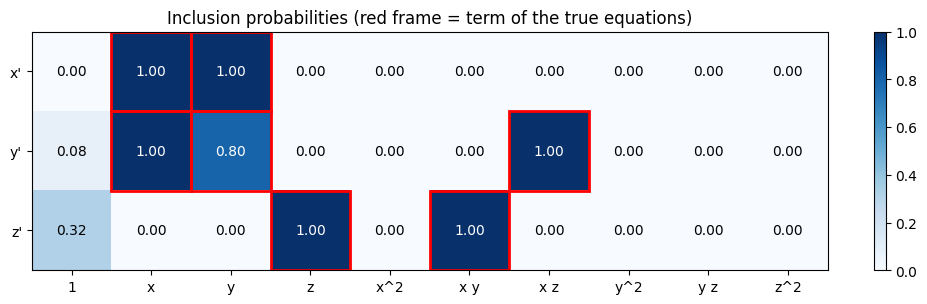

In [36]:
model_ens = fit_sindy(X_noisy, diff_method=smoothed, ensemble=True)   # same 10% dataset as in 6.1
inclusion = np.mean(np.array(model_ens.optimizer.coef_list) != 0, axis=0)
features = model_ens.get_feature_names()

print("Ensemble model (median coefficients):")
model_ens.print()

fig, ax = plt.subplots(figsize=(10, 3))
im = ax.imshow(inclusion, cmap="Blues", vmin=0, vmax=1)
for i in range(3):
    for j in range(len(features)):
        ax.text(j, i, f"{inclusion[i, j]:.2f}", ha="center", va="center",
                color="white" if inclusion[i, j] > 0.6 else "black")
        if TRUE_COEF[i, j] != 0:   # frame the terms that are in the true equations
            ax.add_patch(plt.Rectangle((j - 0.5, i - 0.5), 1, 1, fill=False, ec="red", lw=2))
ax.set_xticks(range(len(features)), features)
ax.set_yticks(range(3), ["x'", "y'", "z'"])
ax.set_title("Inclusion probabilities (red frame = term of the true equations)")
fig.colorbar(im, ax=ax, fraction=0.02)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/lorenz_inclusion_probabilities.png", dpi=200, bbox_inches="tight")
plt.show()

duration  samples  switches |       clean data |                 1% noise
                            | correct? max err |  success rate median err
    0.25      125         1 |    False 189.825 |            0%   6154.350
    0.50      250         1 |    False   8.071 |            0%    134.541
    1.00      500         1 |     True   0.005 |            0%      3.592
    2.00     1000         1 |     True   0.006 |           20%      1.208
    3.00     1500         2 |     True   0.007 |           80%      0.168
    5.00     2500         3 |     True   0.007 |          100%      0.119
   10.00     5000         5 |     True   0.008 |          100%      0.052


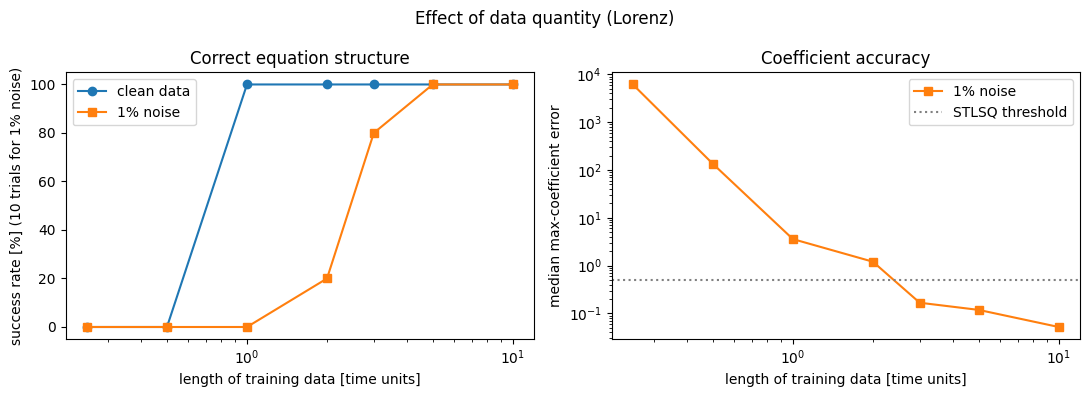

In [37]:
durations = [0.25, 0.5, 1, 2, 3, 5, 10]        # in time units

dq_results = []
print(f"{'duration':>8} {'samples':>8} {'switches':>9} | {'clean data':>16} | {'1% noise':>24}")
print(f"{'':>8} {'':>8} {'':>9} | {'correct?':>8} {'max err':>7} | {'success rate':>13} {'median err':>10}")
for T in durations:
    n = int(T / dt)
    n_switch = np.sum(switch_times < T)
    ok_clean, err_clean = run_trials(0.0, n_samples=n, n_trials=1)
    sr, med_err = run_trials(0.01, n_samples=n)
    dq_results.append((T, ok_clean, sr, med_err))
    print(f"{T:8.2f} {n:8d} {n_switch:9d} | {str(bool(ok_clean)):>8} {err_clean:7.3f} | {sr*100:12.0f}% {med_err:10.3f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(durations, [r[1] * 100 for r in dq_results], "o-", label="clean data")
ax[0].plot(durations, [r[2] * 100 for r in dq_results], "s-", label="1% noise")
ax[0].set_ylabel(f"success rate [%] ({N_TRIALS} trials for 1% noise)"); ax[0].set_ylim(-5, 105)
ax[0].set_title("Correct equation structure"); ax[0].legend()
ax[1].plot(durations, [r[3] for r in dq_results], "s-", color="C1", label="1% noise")
ax[1].axhline(0.5, color="gray", ls=":", label="STLSQ threshold")
ax[1].set_yscale("log"); ax[1].set_ylabel("median max-coefficient error")
ax[1].set_title("Coefficient accuracy"); ax[1].legend()
for a in ax:
    a.set_xscale("log"); a.set_xlabel("length of training data [time units]")
fig.suptitle("Effect of data quantity (Lorenz)")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/lorenz_data_quantity.png", dpi=200, bbox_inches="tight")
plt.show()

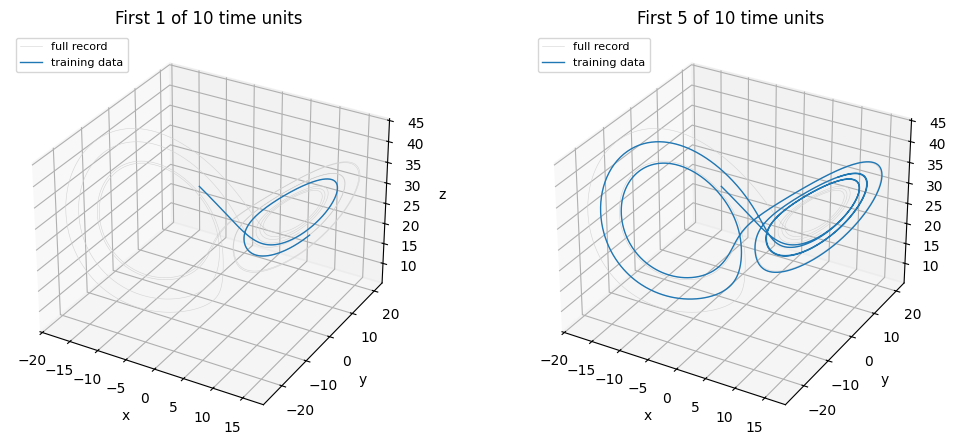

--- first 1 time unit (500 samples), 1% noise ---
(x)' = -9.982 x +  10.000 y
(y)' =  0.745 1 +  27.626 x + -1.042 y + -0.990 x z
(z)' = -44.112 1 + -4.795 x +  1.207 x y

--- full record (5000 samples), same 1% noise ---
(x)' = -9.992 x +  9.992 y
(y)' =  27.927 x + -0.988 y + -0.998 x z
(z)' = -2.662 z +  0.999 x y


In [38]:
fig = plt.figure(figsize=(11, 4.5))
for k, T in enumerate([1, 5]):
    n = int(T / dt)
    ax = fig.add_subplot(1, 2, k + 1, projection="3d")
    ax.plot(X[:, 0], X[:, 1], X[:, 2], color="lightgray", lw=0.4, label="full record")
    ax.plot(X[:n, 0], X[:n, 1], X[:n, 2], color="C0", lw=1.0, label="training data")
    ax.set_xlabel("x"); ax.set_ylabel("y"); ax.set_zlabel("z")
    ax.set_title(f"First {T} of 10 time units"); ax.legend(loc="upper left", fontsize=8)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/lorenz_data_coverage.png", dpi=200, bbox_inches="tight")
plt.show()

n = int(1 / dt)
X_noisy = noisy_copy(0.01, trial=0)
print(f"--- first 1 time unit ({n} samples), 1% noise ---")
fit_sindy(X_noisy[:n]).print()
print(f"\n--- full record ({len(t)} samples), same 1% noise ---")
fit_sindy(X_noisy).print()